# Anexo de verificación — EP1, Caso 2
### Salud: costos médicos y bienestar del paciente

**SCY1102 — Gestión de Proyectos de Datos · Duoc UC**
Integrantes: Moira Bittner, Nicolás Carrasco, Martín Corvalán, Martín Naranjo · Docente: Anibal Sotelo

---

Este cuaderno reproduce **todas las cifras** que aparecen en el informe de factibilidad. Cada sección
calcula un dato y lo contrasta con el valor que citamos en el documento, de modo que cualquiera pueda
verificar que no inventamos nada. La última sección resume la comparación en una tabla.

**Cómo ejecutarlo:** dejar `insurance.csv` en la carpeta `data/` del repositorio y correr las celdas en orden
(`Kernel → Restart & Run All`). Requiere `pandas`, `numpy`, `scikit-learn` y `matplotlib`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

SEMILLA = 42   # fijamos la semilla para que los resultados sean siempre los mismos

# Paleta y estilo comunes a todos los gráficos
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"
TINTA, TINTA2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d5d4cf", "axes.labelcolor": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TINTA2, "ytick.color": TINTA2,
    "text.color": TINTA, "font.size": 10,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

# Registro de comprobaciones: se va llenando a lo largo del cuaderno
comprobaciones = []
def verificar(concepto, valor_informe, valor_calculado, tolerancia=0.51, unidad=""):
    ok = abs(valor_informe - valor_calculado) <= tolerancia
    comprobaciones.append({
        "Dato citado en el informe": concepto,
        "Informe": f"{valor_informe:,.1f}{unidad}",
        "Calculado": f"{valor_calculado:,.1f}{unidad}",
        "¿Coincide?": "Sí" if ok else "NO",
    })
    return ok

df = pd.read_csv("../data/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1. Calidad del conjunto de datos

El informe afirma: *1.338 registros, 7 variables, sin valores nulos y un solo registro duplicado.*

In [2]:
print(f"Registros: {df.shape[0]}   Variables: {df.shape[1]}")
print(f"Valores nulos en total: {df.isna().sum().sum()}")
print(f"Registros duplicados: {df.duplicated().sum()}")
print()
print("Tipos de dato y variables:")
print(df.dtypes.to_string())

verificar("Número de registros", 1338, df.shape[0], 0)
verificar("Valores nulos", 0, df.isna().sum().sum(), 0)
verificar("Registros duplicados", 1, df.duplicated().sum(), 0)

Registros: 1338   Variables: 7
Valores nulos en total: 0
Registros duplicados: 1

Tipos de dato y variables:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64


np.True_

## 2. Distribución del gasto: la asimetría que justifica el análisis

El informe afirma: *gasto medio USD 13.270, mediana USD 9.382, y el decil más costoso concentra el 32,0 % del gasto total.*

La diferencia entre media y mediana es lo que revela que un grupo pequeño concentra el gasto; por eso
el proyecto tiene sentido financiero, pero también por eso el modelo puede volverse discriminatorio.

In [3]:
media = df.charges.mean()
mediana = df.charges.median()
umbral_decil = df.charges.quantile(0.90)
decil_sup = df[df.charges >= umbral_decil]
part_decil = decil_sup.charges.sum() / df.charges.sum() * 100

print(f"Gasto medio anual .................. USD {media:>10,.0f}")
print(f"Mediana ........................... USD {mediana:>10,.0f}")
print(f"Umbral del decil más costoso ...... USD {umbral_decil:>10,.0f}")
print(f"Afiliados en ese decil ............ {len(decil_sup):>14}")
print(f"Gasto medio de ese decil .......... USD {decil_sup.charges.mean():>10,.0f}")
print(f"Participación en el gasto total ... {part_decil:>13.1f} %")

verificar("Gasto medio anual (USD)", 13270, media, 1)
verificar("Mediana del gasto (USD)", 9382, mediana, 1)
verificar("Gasto medio del decil superior (USD)", 42379, decil_sup.charges.mean(), 1)
verificar("Participación del decil superior (%)", 32.0, part_decil, 0.1)

Gasto medio anual .................. USD     13,270
Mediana ........................... USD      9,382
Umbral del decil más costoso ...... USD     34,832
Afiliados en ese decil ............            134
Gasto medio de ese decil .......... USD     42,379
Participación en el gasto total ...          32.0 %


np.True_

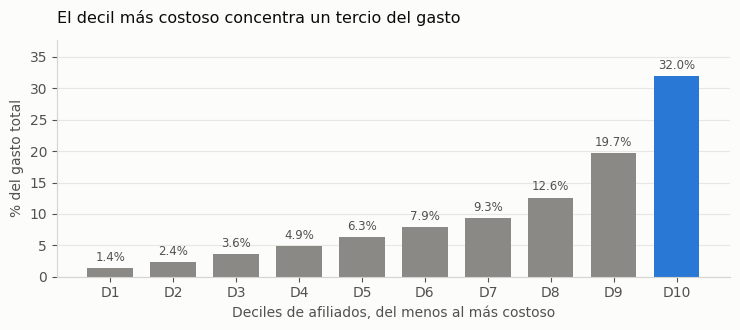

In [4]:
# Cuánto del gasto total aporta cada decil de afiliados, ordenados de menor a mayor costo
decil = pd.qcut(df.charges, 10, labels=[f"D{i}" for i in range(1, 11)])
aporte = df.groupby(decil, observed=True).charges.sum() / df.charges.sum() * 100

fig, ax = plt.subplots(figsize=(7.5, 3.4))
colores = [GRIS] * 9 + [AZUL]
barras = ax.bar(aporte.index.astype(str), aporte.values, color=colores, width=0.72)
ax.bar_label(barras, fmt="%.1f%%", padding=3, fontsize=8.5, color=TINTA2)
ax.set_title("El decil más costoso concentra un tercio del gasto", fontsize=11.5, pad=12, loc="left")
ax.set_xlabel("Deciles de afiliados, del menos al más costoso")
ax.set_ylabel("% del gasto total")
ax.set_ylim(0, aporte.max() * 1.18)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 3. Sesgo de representación

El informe afirma: *edades entre 18 y 64 años (sin mayores de 65), 52,8 % de la muestra con IMC ≥ 30,
sexo codificado de forma binaria y regiones de Estados Unidos.*

Esto importa porque el tramo de mayor gasto sanitario —los adultos mayores— sencillamente no está en
los datos, y porque la proporción de obesidad es muy superior a la de una población general.

In [5]:
print(f"Rango de edad ................. {df.age.min()} a {df.age.max()} años")
print(f"Mayores de 65 en la muestra ... {(df.age > 65).sum()}")
print(f"IMC ≥ 30 ...................... {(df.bmi >= 30).mean()*100:.1f} % de la muestra")
print(f"Categorías de sexo ............ {sorted(df.sex.unique())}")
print(f"Regiones ...................... {sorted(df.region.unique())}")
print()
print("Fumadores:")
print((df.smoker.value_counts(normalize=True)*100).round(1).to_string())

verificar("Edad mínima", 18, df.age.min(), 0)
verificar("Edad máxima", 64, df.age.max(), 0)
verificar("Afiliados mayores de 65", 0, (df.age > 65).sum(), 0)
verificar("Muestra con IMC ≥ 30 (%)", 52.8, (df.bmi >= 30).mean()*100, 0.1)
verificar("Fumadores en la muestra (%)", 20.5, (df.smoker == "yes").mean()*100, 0.1)

Rango de edad ................. 18 a 64 años
Mayores de 65 en la muestra ... 0
IMC ≥ 30 ...................... 52.8 % de la muestra
Categorías de sexo ............ ['female', 'male']
Regiones ...................... ['northeast', 'northwest', 'southeast', 'southwest']

Fumadores:
smoker
no     79.5
yes    20.5


np.True_

## 4. La región como proxy socioeconómico

El informe afirma: *southeast concentra la mayor proporción de fumadores (25,0 % frente a 17,8 % en
northwest y southwest) y el gasto medio más alto (USD 14.735).*

Como el conjunto no tiene ingreso ni nivel educacional, la región termina absorbiendo esas diferencias.
El riesgo es que el modelo penalice un territorio por su composición social y no por un riesgo verificado.

In [6]:
por_region = pd.DataFrame({
    "Afiliados": df.groupby("region").size(),
    "% fumadores": df.groupby("region").smoker.apply(lambda s: (s == "yes").mean()*100).round(1),
    "Gasto medio (USD)": df.groupby("region").charges.mean().round(0),
}).sort_values("Gasto medio (USD)", ascending=False)
display(por_region)

verificar("% fumadores en southeast", 25.0, por_region.loc["southeast", "% fumadores"], 0.1)
verificar("Gasto medio en southeast (USD)", 14735, por_region.loc["southeast", "Gasto medio (USD)"], 1)

,Afiliados,% fumadores,Gasto medio (USD)
region,,,
southeast,364,25.0,14735.0
northeast,324,20.7,13406.0
northwest,325,17.8,12418.0
southwest,325,17.8,12347.0


np.True_

## 5. El efecto del tabaquismo y su interacción con la obesidad

El informe afirma: *un fumador gasta en promedio USD 32.050 frente a USD 8.434 de un no fumador (3,8 veces),
y un fumador con IMC ≥ 30 promedia USD 41.558 frente a USD 21.363 de un fumador no obeso.*

In [7]:
por_fumador = df.groupby("smoker").charges.agg(["size", "mean", "median"]).round(0)
por_fumador.columns = ["Afiliados", "Gasto medio (USD)", "Mediana (USD)"]
por_fumador.index = ["No fumador", "Fumador"]
display(por_fumador)

razon = df[df.smoker=="yes"].charges.mean() / df[df.smoker=="no"].charges.mean()
print(f"Un fumador gasta {razon:.1f} veces lo que gasta un no fumador.\n")

df["obeso"] = df.bmi >= 30
cruce = df.groupby(["smoker", "obeso"]).charges.mean().round(0).unstack()
cruce.columns = ["IMC < 30", "IMC ≥ 30"]; cruce.index = ["No fumador", "Fumador"]
display(cruce)

verificar("Gasto medio de un fumador (USD)", 32050, df[df.smoker=="yes"].charges.mean(), 1)
verificar("Gasto medio de un no fumador (USD)", 8434, df[df.smoker=="no"].charges.mean(), 1)
verificar("Fumador con IMC ≥ 30 (USD)", 41558, cruce.loc["Fumador", "IMC ≥ 30"], 1)
verificar("Fumador con IMC < 30 (USD)", 21363, cruce.loc["Fumador", "IMC < 30"], 1)

,Afiliados,Gasto medio (USD),Mediana (USD)
No fumador,1064,8434.0,7345.0
Fumador,274,32050.0,34456.0


Un fumador gasta 3.8 veces lo que gasta un no fumador.



,IMC < 30,IMC ≥ 30
No fumador,7977.0,8843.0
Fumador,21363.0,41558.0


np.True_

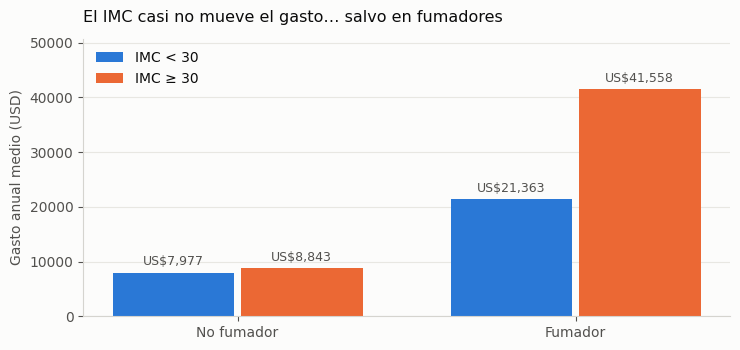

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(2); ancho = 0.36
delgado = [cruce.loc["No fumador", "IMC < 30"], cruce.loc["Fumador", "IMC < 30"]]
obeso   = [cruce.loc["No fumador", "IMC ≥ 30"], cruce.loc["Fumador", "IMC ≥ 30"]]

b1 = ax.bar(x - ancho/2 - 0.01, delgado, ancho, label="IMC < 30", color=AZUL)
b2 = ax.bar(x + ancho/2 + 0.01, obeso,   ancho, label="IMC ≥ 30", color=NARANJA)
for b in (b1, b2):
    ax.bar_label(b, fmt="US$%,.0f".replace(",", ""), labels=[f"US${v:,.0f}" for v in b.datavalues],
                 padding=3, fontsize=9, color=TINTA2)

ax.set_xticks(x, ["No fumador", "Fumador"])
ax.set_title("El IMC casi no mueve el gasto… salvo en fumadores", fontsize=11.5, pad=12, loc="left")
ax.set_ylabel("Gasto anual medio (USD)")
ax.set_ylim(0, max(obeso) * 1.22)
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 6. Los modelos

El informe afirma: *regresión lineal R² = 0,767 y MAE = USD 4.244; Random Forest R² = 0,850 y
MAE = USD 2.610; predecir el promedio de la cartera da un MAE de USD 9.253, de modo que el modelo
reduce el error en un 71,8 %.*

In [9]:
X = pd.get_dummies(df.drop(columns=["charges", "obeso"]), drop_first=True)
y = df.charges
X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(
    X, y, df.index, test_size=0.25, random_state=SEMILLA)

# Modelo de referencia: predecir siempre el promedio del conjunto de entrenamiento
pred_base = np.full(len(y_te), y_tr.mean())
mae_base = mean_absolute_error(y_te, pred_base)

lineal = LinearRegression().fit(X_tr, y_tr)
pred_lin = lineal.predict(X_te)

bosque = RandomForestRegressor(n_estimators=300, random_state=SEMILLA).fit(X_tr, y_tr)
pred_rf = bosque.predict(X_te)

resumen = pd.DataFrame({
    "R²":  ["—", round(r2_score(y_te, pred_lin), 3), round(r2_score(y_te, pred_rf), 3)],
    "MAE (USD)": [round(mae_base), round(mean_absolute_error(y_te, pred_lin)),
                  round(mean_absolute_error(y_te, pred_rf))],
}, index=["Predecir el promedio (referencia)", "Regresión lineal", "Random Forest"])
display(resumen)

mae_rf = mean_absolute_error(y_te, pred_rf)
reduccion = (1 - mae_rf / mae_base) * 100
print(f"El Random Forest reduce el error respecto de la referencia en {reduccion:.1f} %.")

verificar("R² de la regresión lineal", 0.767, r2_score(y_te, pred_lin), 0.001)
verificar("MAE de la regresión lineal (USD)", 4244, mean_absolute_error(y_te, pred_lin), 1)
verificar("R² del Random Forest", 0.850, r2_score(y_te, pred_rf), 0.001)
verificar("MAE del Random Forest (USD)", 2610, mae_rf, 1)
verificar("MAE de la referencia (USD)", 9253, mae_base, 1)
verificar("Reducción del error (%)", 71.8, reduccion, 0.1)

,R²,MAE (USD)
Predecir el promedio (referencia),—,9253
Regresión lineal,0.767,4244
Random Forest,0.85,2610


El Random Forest reduce el error respecto de la referencia en 71.8 %.


True

## 7. Auditoría de equidad — el hallazgo central del informe

Ésta es la comprobación más importante y la razón por la que el informe insiste en reportar métricas
desagregadas. El informe afirma: *el MAE del modelo lineal es de USD 3.223 en no fumadores y de
USD 8.250 en fumadores (2,6 veces mayor), y el Random Forest, aunque reduce la brecha, sobreestima
sistemáticamente en +USD 962 a los fumadores y en +USD 724 a la región southeast.*

Un R² global de 0,85 se ve excelente y **oculta por completo** que el modelo es mucho menos confiable
justamente con el subgrupo minoritario que más pagaría.

In [10]:
aud = df.loc[idx_te].copy()
aud["pred_lineal"] = pred_lin
aud["pred_bosque"] = pred_rf

def auditar(columna, etiquetas=None):
    filas = []
    for grupo, sub in aud.groupby(columna):
        filas.append({
            columna: grupo,
            "n": len(sub),
            "MAE lineal": round((sub.pred_lineal - sub.charges).abs().mean()),
            "MAE bosque": round((sub.pred_bosque - sub.charges).abs().mean()),
            "Sesgo medio bosque": round((sub.pred_bosque - sub.charges).mean()),
        })
    t = pd.DataFrame(filas).set_index(columna)
    if etiquetas: t.index = [etiquetas.get(i, i) for i in t.index]
    return t

for col, etiq in [("smoker", {"no": "No fumador", "yes": "Fumador"}),
                  ("sex", {"female": "Mujer", "male": "Hombre"}),
                  ("region", None)]:
    print(f"── Error desagregado por {col} ──")
    display(auditar(col, etiq))

a_fum = auditar("smoker", {"no": "No fumador", "yes": "Fumador"})
brecha = a_fum.loc["Fumador", "MAE lineal"] / a_fum.loc["No fumador", "MAE lineal"]
print(f"El modelo lineal se equivoca {brecha:.1f} veces más con los fumadores que con los no fumadores.")

verificar("MAE lineal en no fumadores (USD)", 3223, a_fum.loc["No fumador", "MAE lineal"], 1)
verificar("MAE lineal en fumadores (USD)", 8250, a_fum.loc["Fumador", "MAE lineal"], 1)
verificar("Brecha de error entre subgrupos (veces)", 2.6, brecha, 0.05)
verificar("Sesgo del bosque en fumadores (USD)", 962, a_fum.loc["Fumador", "Sesgo medio bosque"], 1)
verificar("Sesgo del bosque en southeast (USD)", 724,
          auditar("region").loc["southeast", "Sesgo medio bosque"], 1)

── Error desagregado por smoker ──


,n,MAE lineal,MAE bosque,Sesgo medio bosque
No fumador,267,3223,2588,168
Fumador,68,8250,2695,962


── Error desagregado por sex ──


,n,MAE lineal,MAE bosque,Sesgo medio bosque
Mujer,165,3755,2484,-80
Hombre,170,4718,2732,726


── Error desagregado por region ──


,n,MAE lineal,MAE bosque,Sesgo medio bosque
region,,,,
northeast,73,4145,2553,-464
northwest,79,3842,2534,-10
southeast,105,5168,2548,724
southwest,78,3499,2824,884


El modelo lineal se equivoca 2.6 veces más con los fumadores que con los no fumadores.


np.True_

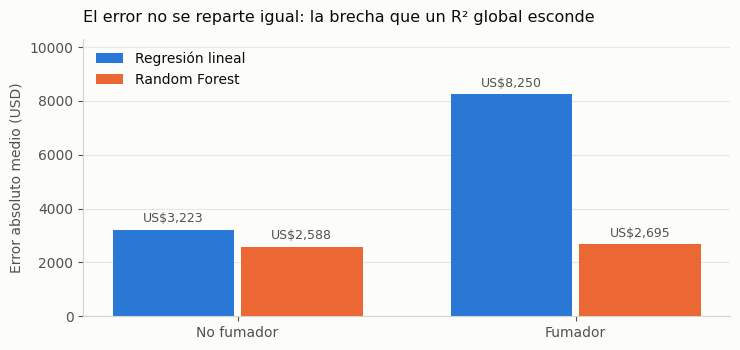

In [11]:
etiquetas = ["No fumador", "Fumador"]
mae_lin = [a_fum.loc[e, "MAE lineal"] for e in etiquetas]
mae_bos = [a_fum.loc[e, "MAE bosque"] for e in etiquetas]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(2); ancho = 0.36
b1 = ax.bar(x - ancho/2 - 0.01, mae_lin, ancho, label="Regresión lineal", color=AZUL)
b2 = ax.bar(x + ancho/2 + 0.01, mae_bos, ancho, label="Random Forest", color=NARANJA)
for b in (b1, b2):
    ax.bar_label(b, labels=[f"US${v:,.0f}" for v in b.datavalues], padding=3, fontsize=9, color=TINTA2)

ax.set_xticks(x, etiquetas)
ax.set_title("El error no se reparte igual: la brecha que un R² global esconde",
             fontsize=11.5, pad=12, loc="left")
ax.set_ylabel("Error absoluto medio (USD)")
ax.set_ylim(0, max(mae_lin) * 1.25)
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 8. A quién señala el modelo

El informe afirma: *el 97,8 % del decil de mayor costo corresponde a fumadores.*

Es el dato que sostiene el argumento ético: «priorizar al 10 % más costoso» equivale, en la práctica,
a segmentar por una conducta de salud. Sirve para focalizar prevención, pero sería discriminatorio
para tarificar o denegar cobertura.

In [12]:
pct_fum_decil = (decil_sup.smoker == "yes").mean() * 100
print(f"Afiliados en el decil más costoso ...... {len(decil_sup)}")
print(f"De ellos, fumadores .................... {pct_fum_decil:.1f} %")
print(f"Proporción de fumadores en la muestra .. {(df.smoker=='yes').mean()*100:.1f} %")

verificar("Fumadores en el decil superior (%)", 97.8, pct_fum_decil, 0.1)

Afiliados en el decil más costoso ...... 134
De ellos, fumadores .................... 97.8 %
Proporción de fumadores en la muestra .. 20.5 %


np.True_

## 9. ¿Cuánto cuesta excluir el sexo del modelo?

El informe propone excluir la variable `sex`, porque el Tribunal Constitucional y la Corte Suprema
impiden diferenciar por sexo y edad en la tarificación de isapres, y sostiene que *el costo en
precisión es asumible*. Aquí lo medimos en vez de suponerlo.

In [13]:
X_sin_sexo = X.drop(columns=[c for c in X.columns if c.startswith("sex_")])
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(
    X_sin_sexo, y, test_size=0.25, random_state=SEMILLA)

bosque_sin = RandomForestRegressor(n_estimators=300, random_state=SEMILLA).fit(Xs_tr, ys_tr)
r2_sin = r2_score(ys_te, bosque_sin.predict(Xs_te))
r2_con = r2_score(y_te, pred_rf)

print(f"R² con la variable sexo ..... {r2_con:.4f}")
print(f"R² sin la variable sexo ..... {r2_sin:.4f}")
print(f"Diferencia .................. {abs(r2_con - r2_sin):.4f} puntos de R²")
print()
print("Conclusión: excluir el sexo prácticamente no degrada el modelo, así que la medida de")
print("mitigación propuesta en el informe es viable y no tiene un costo técnico relevante.")

R² con la variable sexo ..... 0.8498
R² sin la variable sexo ..... 0.8529
Diferencia .................. 0.0031 puntos de R²

Conclusión: excluir el sexo prácticamente no degrada el modelo, así que la medida de
mitigación propuesta en el informe es viable y no tiene un costo técnico relevante.


## 10. Resumen de la verificación

Contraste final entre lo que dice el informe y lo que arrojan los datos.

In [14]:
tabla = pd.DataFrame(comprobaciones)
total, correctas = len(tabla), (tabla["¿Coincide?"] == "Sí").sum()
display(tabla.style.hide(axis="index"))
print(f"\n{correctas} de {total} cifras del informe se reproducen exactamente con este cuaderno.")
if correctas < total:
    print("\nRevisar las filas marcadas con NO.")

Dato citado en el informe,Informe,Calculado,¿Coincide?
Número de registros,"1,338.0","1,338.0",Sí
Valores nulos,0.0,0.0,Sí
Registros duplicados,1.0,1.0,Sí
Gasto medio anual (USD),"13,270.0","13,270.4",Sí
Mediana del gasto (USD),"9,382.0","9,382.0",Sí
Gasto medio del decil superior (USD),"42,379.0","42,378.7",Sí
Participación del decil superior (%),32.0,32.0,Sí
Edad mínima,18.0,18.0,Sí
Edad máxima,64.0,64.0,Sí
Afiliados mayores de 65,0.0,0.0,Sí



30 de 30 cifras del informe se reproducen exactamente con este cuaderno.


---

### Nota metodológica

Todos los modelos usan la misma partición (75 % entrenamiento / 25 % prueba) con `random_state=42`,
de modo que los resultados son reproducibles. Las métricas por subgrupo se calculan **sobre el conjunto
de prueba**, nunca sobre los datos con los que el modelo se entrenó.

Dos advertencias que el informe también recoge y que este cuaderno no puede resolver:

1. Los datos son de Estados Unidos y no incluyen a mayores de 65 años, así que estos resultados
   valen como prototipo y no como evidencia sobre una cartera chilena.
2. La variable objetivo es el **costo facturado**, no la necesidad de salud. Aunque las métricas se
   vean bien, el modelo hereda el sesgo de proxy documentado por Obermeyer et al. (2019).